# 01 · Lecture et exploration des données

On veut estimer la probabilité qu'une demande de prêt immobilier soit acceptée (`accepted = 1`), à partir de données HMDA américaines. La métrique est l'AUC. Il y a 105 000 lignes d'apprentissage, 45 000 de test et 56 variables.

Ce notebook vérifie les CSV, explore les données et écrit dans `artifacts/01_data_exploration/` une version préparée commune à tous les notebooks : les 56 variables typées, la cible, les identifiants et cinq plis fixes. Aucune ligne n'est supprimée et la cible ne sert à construire aucune variable.

Les cinq notebooks : 01 données → 02 variables → 03 choix des modèles → 04 modèle final → 05 analyse des erreurs. Les CSV sont dans `data/`, les résultats dans `artifacts/<nom du notebook>/`.

Si les fichiers préparés existent déjà, ils sont vérifiés et non réécrits. La section 8 entraîne un petit modèle sur CPU.

In [1]:
# Environnement, chemins et fonctions partagés par les cinq notebooks
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib
import importlib.metadata
import json
import os
import platform
import shutil
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False


def find_project_dir():
    candidates = []
    if os.environ.get('HMDA_PROJECT_DIR'):
        candidates.append(Path(os.environ['HMDA_PROJECT_DIR']))
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    candidates.append(Path('/content/drive/MyDrive/Colab Notebooks/demandes-de-pret-immobilier-aux-etats-unis'))
    for candidate in candidates:
        if (candidate / 'data' / 'train.csv').is_file() and (candidate / 'data' / 'test.csv').is_file():
            return candidate.expanduser().resolve()
    raise FileNotFoundError('Projet introuvable (data/train.csv et data/test.csv requis) ; définir HMDA_PROJECT_DIR')


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / 'data'                                        # CSV sources (lecture seule)
ARTIFACTS = PROJECT_DIR / 'artifacts'                                  # Résultats dans un sous-dossier par notebook
PREPARED_DIR = ARTIFACTS / '01_data_exploration'                       # 01 : données préparées et schéma fixe
FEATURE_DIR = ARTIFACTS / '02_feature_engineering' / 'feature_store'   # 02 : feature store
SEED = 42
CATBOOST_VERSION = '1.2.10'
GPU_NAME = None
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})


def ensure_catboost():
    """Installe et importe la version fixée de CatBoost pour le réentraînement."""
    global catboost
    try:
        installed = importlib.metadata.version('catboost')
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != CATBOOST_VERSION:
        if 'catboost' in sys.modules:
            raise RuntimeError('Une autre version de CatBoost est déjà chargée ; redémarrer puis relancer le notebook')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', f'catboost=={CATBOOST_VERSION}'])
        importlib.invalidate_caches()
    import catboost as catboost_module
    if catboost_module.__version__ != CATBOOST_VERSION:
        raise RuntimeError(f'CatBoost {CATBOOST_VERSION} requis ; version chargée : {catboost_module.__version__}')
    catboost = catboost_module
    return catboost_module


def ensure_gpu():
    """Vérifie la présence du GPU NVIDIA avant le réentraînement."""
    global GPU_NAME
    if shutil.which('nvidia-smi') is None:
        raise RuntimeError('GPU requis : choisir un GPU T4 dans le type de session Colab, puis relancer')
    probe = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                           text=True, capture_output=True, check=False)
    if probe.returncode != 0 or not probe.stdout.strip():
        raise RuntimeError('GPU NVIDIA indisponible : choisir un T4 puis relancer')
    GPU_NAME = probe.stdout.strip().splitlines()[0]
    return GPU_NAME


print('Projet :', PROJECT_DIR.name)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')

Projet : demandes-de-pret-immobilier-aux-etats-unis
Python 3.13.5 | pandas 2.2.3 | numpy 2.1.3


In [2]:
"""Identifiants de stockage historiques et libellés descriptifs.

Les valeurs assurent la reprise exacte des artefacts existants. Les paramètres,
les features et leur ordre sont définis dans les cellules métier.
Cette cellule est intégrée à chaque notebook : aucun import local requis.
"""

MODEL_DEPTH6_INITIAL = 'M0_C11_all'
MODEL_DEPTH6_ENRICHED = 'M1_C11_G7'
MODEL_DEPTH8_ENRICHED = 'M2_C7_G7'
MODEL_DEPTH6_REDUCED = 'M3_C11_lean'
FEATURE_SET_INITIAL = 'ROUND1_ALL'
FEATURE_SET_ENRICHED = 'G7'
FEATURE_SET_REDUCED = 'LEAN'
ENSEMBLE_THREE_MODELS_SEED42 = 'B13_seed42'
ENSEMBLE_MULTISEED = 'B_seeds'
ENSEMBLE_MULTISEED_PREFIX = 'B_seeds_'
ENSEMBLE_FULL_MULTISEED = 'full_Bseeds'
MODEL_INITIAL_POOL_LABEL = 'M0'
LEARNING_CURVE_SUBSET = 'LC_sub80'
LEARNING_CURVE_FULL = 'LC_full'
REDUCED_MODEL_CV_AUC = 'M3_in_13'
BASELINE_CATBOOST_DEPTH6 = 'CatBoost_R1'
BASELINE_CATBOOST_DEPTH8 = 'CatBoost_R2'
LIGHTGBM_LEAVES31 = 'L1_lgbm_leaves31'
LIGHTGBM_LEAVES127 = 'L2_lgbm_leaves127'
OBSERVED_LABELS_ONLY = 'A_base'
SOFT_PSEUDO_LABELS = 'A_pseudo'
LEARNING_CURVE_RUN_PATTERN = 'LC_*__fold?.json'
LEARNING_CURVE_FULL_PATTERN = 'LC_full__fold?.json'
REDUCED_MODEL_RUN_PATTERN = 'M3_C11_lean__fold?.json'
LIGHTGBM_RUN_PATTERN = 'L*_lgbm_*__fold?.json'
PSEUDO_LABEL_RUN_PATTERN = 'A_*__fold?.json'
FULL_ENSEMBLE_SUBMISSION = 'submission_full_Bseeds.csv'
ABLATION_ORIGINAL = 'F0_base'
ABLATION_ADD_DTI = 'F1_dti'
ABLATION_ADD_LTV = 'F2_ltv'
ABLATION_ADD_INCOME = 'F3_income'
ABLATION_ADD_MISSINGNESS = 'F4_missing'
ABLATION_ADD_GEOGRAPHIC_COUNTS = 'F5_freq'
ABLATION_INITIAL = 'F6_all'
ABLATION_INITIAL_REFERENCE = 'G0_all'
ABLATION_ADD_LTV_PRECISION = 'G1_precision'
ABLATION_ADD_LTV_THRESHOLDS = 'G2_thresholds'
ABLATION_ADD_IMPLIED_VALUE = 'G3_implied'
ABLATION_ADD_TERM = 'G4_term'
ABLATION_ENRICHED_WITH_COUNTS = 'G5_round2_all'
ABLATION_CORE_WITHOUT_COUNTS = 'G6_nofreq'
ABLATION_ENRICHED = 'G7_nofreq_round2_all'
ABLATION_ENRICHED_REFERENCE = 'H0_G7'
ABLATION_ADD_PRODUCT_FLAGS = 'H1_purpose'
ABLATION_ADD_LTV_CONSISTENCY = 'H2_ltv_consistency'
ABLATION_ADD_RISK_INTERACTIONS = 'H3_risk_layers'
ABLATION_ADD_TRACT_INCOME = 'H4_tract_income'
ABLATION_ALL_PRODUCT_RISK = 'H5_round3_all'
TUNING_DEPTH8_FIXED1600 = 'B0_R2_fixed1600'
TUNING_DEPTH8_LR005_L2_3 = 'C1_d8_lr05_l2_3_es'
TUNING_DEPTH6_LR003_L2_10 = 'C6_d6_lr03_l2_10'
TUNING_DEPTH8_LR003_L2_10 = 'C3_d8_lr03_l2_10'
TUNING_DEPTH8_LR003_L2_3 = 'C2_d8_lr03_l2_3'
TUNING_DEPTH8_LR003_L2_30 = 'C4_d8_lr03_l2_30'
TUNING_DEPTH8_BERNOULLI80 = 'C7_d8_lr03_l2_10_sub80'
TUNING_DEPTH8_WITH_DTI = 'C8_d8_lr03_l2_10_DTI'
TUNING_DEPTH10_LR003_L2_10 = 'C5_d10_lr03_l2_10'
TUNING_DEPTH8_LR002_L2_10 = 'C9_d8_lr02_l2_10'
TUNING_DEPTH8_L2_30_BERNOULLI80 = 'C10_d8_lr03_l2_30_sub80'
TUNING_DEPTH6_BERNOULLI80 = 'C11_d6_lr03_l2_10_sub80'
TRAINING_STANDARD = 'V0_base'
TRAINING_ORDERED = 'V1_ordered'
TRAINING_NEWTON_SCORE = 'V2_newtonL2'
TRAINING_DEPTHWISE = 'V3_depthwise'
TRAINING_LOSSGUIDE = 'V4_lossguide'
TRAINING_POISSON = 'V5_poisson'
TRAINING_ROWS066 = 'V6_sub066'
TRAINING_BINS254 = 'V7_border254'
TRAINING_NO_CATEGORY_COMBINATIONS = 'V8_ctr1'
TRAINING_DROP_REDUNDANT_DEMOGRAPHICS = 'V9_drop_demo'
MEAN_GAIN_VS_SOURCE_FEATURES = 'mean_delta_vs_F0'
FOLDS_BETTER_THAN_SOURCE_FEATURES = 'folds_better_than_F0'
MEAN_GAIN_VS_INITIAL_FEATURES = 'mean_delta_vs_G0'
FOLDS_BETTER_THAN_INITIAL_FEATURES = 'folds_better_than_G0'
MEAN_GAIN_VS_ENRICHED_FEATURES = 'mean_delta_vs_H0'
FOLDS_BETTER_THAN_ENRICHED_FEATURES = 'folds_better_than_H0'
MEAN_GAIN_VS_FIXED_ITERATIONS = 'mean_delta_vs_B0'
FOLDS_BETTER_THAN_FIXED_ITERATIONS = 'folds_better_than_B0'
MEAN_GAIN_VS_STANDARD_BOOSTING = 'mean_delta_vs_V0'
FOLDS_BETTER_THAN_STANDARD_BOOSTING = 'folds_better_than_V0'
GAIN_VS_THREE_MODEL_ENSEMBLE = 'delta_vs_B13'
FOLDS_BETTER_THAN_THREE_MODEL_ENSEMBLE = 'folds_better_than_B13'
TABM_ENSEMBLE_SUBMISSION_PREFIX = 'submission_Bseeds_TabM_w'
PURPOSE_ABLATION = 'feature block ablation, fast GPU CatBoost, paired vs F0_base'
PURPOSE_TRAINING_MODES = 'data-efficiency screen on M3 features; inner 15% early stop, score probe model on outer fold'
PURPOSE_TABM = 'TabM-mini (PyTorch) on G7 features; inner 15% early stop, no outer refit'
PURPOSE_FULL_REFIT = 'learning curve (80% vs 100% of outer-train) + full-data refit of M1-M3 x 3 seeds'

DISPLAY_LABELS = {
    MODEL_DEPTH6_INITIAL: 'CatBoost profondeur 6 · variables initiales',
    MODEL_DEPTH6_ENRICHED: 'CatBoost profondeur 6 · variables enrichies',
    MODEL_DEPTH8_ENRICHED: 'CatBoost profondeur 8 · variables enrichies',
    MODEL_DEPTH6_REDUCED: 'CatBoost profondeur 6 · variables réduites',
    FEATURE_SET_INITIAL: 'Variables initiales (68 colonnes)',
    FEATURE_SET_ENRICHED: 'Variables enrichies (72 colonnes)',
    FEATURE_SET_REDUCED: 'Variables réduites (68 colonnes)',
    ENSEMBLE_THREE_MODELS_SEED42: 'Ensemble de trois modèles · graine 42',
    ENSEMBLE_MULTISEED: 'Ensemble de trois modèles et trois graines',
    ENSEMBLE_MULTISEED_PREFIX: 'Ensemble multigraines · ',
    ENSEMBLE_FULL_MULTISEED: 'Ensemble multigraines sur toutes les données',
    MODEL_INITIAL_POOL_LABEL: 'CatBoost profondeur 6 · variables initiales',
    LEARNING_CURVE_SUBSET: 'Apprentissage sur 67 200 lignes',
    LEARNING_CURVE_FULL: 'Apprentissage sur 84 000 lignes',
    REDUCED_MODEL_CV_AUC: 'AUC du modèle réduit en validation croisée',
    BASELINE_CATBOOST_DEPTH6: 'CatBoost profondeur 6',
    BASELINE_CATBOOST_DEPTH8: 'CatBoost profondeur 8',
    LIGHTGBM_LEAVES31: 'LightGBM · 31 feuilles',
    LIGHTGBM_LEAVES127: 'LightGBM · 127 feuilles',
    OBSERVED_LABELS_ONLY: 'Cibles observées uniquement',
    SOFT_PSEUDO_LABELS: 'Pseudo-étiquettes souples',
    LEARNING_CURVE_RUN_PATTERN: 'Courbe d’apprentissage',
    LEARNING_CURVE_FULL_PATTERN: 'Courbe sur 84 000 lignes',
    REDUCED_MODEL_RUN_PATTERN: 'Validation croisée du modèle réduit',
    LIGHTGBM_RUN_PATTERN: 'Modèles LightGBM',
    PSEUDO_LABEL_RUN_PATTERN: 'Comparaison des pseudo-étiquettes',
    FULL_ENSEMBLE_SUBMISSION: 'Soumission de l’ensemble complet',
    ABLATION_ORIGINAL: 'Variables sources',
    ABLATION_ADD_DTI: 'Ajout des bornes DTI',
    ABLATION_ADD_LTV: 'Ajout de la cohérence LTV',
    ABLATION_ADD_INCOME: 'Ajout des ratios de revenu',
    ABLATION_ADD_MISSINGNESS: 'Ajout des valeurs manquantes',
    ABLATION_ADD_GEOGRAPHIC_COUNTS: 'Ajout des fréquences géographiques',
    ABLATION_INITIAL: 'Toutes les variables initiales',
    ABLATION_INITIAL_REFERENCE: 'Référence : variables initiales',
    ABLATION_ADD_LTV_PRECISION: 'Ajout de la précision LTV',
    ABLATION_ADD_LTV_THRESHOLDS: 'Ajout des seuils LTV',
    ABLATION_ADD_IMPLIED_VALUE: 'Ajout de la valeur immobilière implicite',
    ABLATION_ADD_TERM: 'Ajout des variables de durée',
    ABLATION_ENRICHED_WITH_COUNTS: 'Variables enrichies avec fréquences géographiques',
    ABLATION_CORE_WITHOUT_COUNTS: 'Variables initiales sans fréquences géographiques',
    ABLATION_ENRICHED: 'Variables enrichies sans fréquences géographiques',
    ABLATION_ENRICHED_REFERENCE: 'Référence : variables enrichies',
    ABLATION_ADD_PRODUCT_FLAGS: 'Ajout des indicateurs de produit',
    ABLATION_ADD_LTV_CONSISTENCY: 'Ajout de la cohérence des intervalles LTV',
    ABLATION_ADD_RISK_INTERACTIONS: 'Ajout des interactions de risque',
    ABLATION_ADD_TRACT_INCOME: 'Ajout du revenu relatif au secteur',
    ABLATION_ALL_PRODUCT_RISK: 'Ajout de tous les blocs produit et risque',
    TUNING_DEPTH8_FIXED1600: 'Profondeur 8 · 1 600 itérations fixes',
    TUNING_DEPTH8_LR005_L2_3: 'Profondeur 8 · taux 0.05 · L2=3',
    TUNING_DEPTH6_LR003_L2_10: 'Profondeur 6 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR003_L2_10: 'Profondeur 8 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR003_L2_3: 'Profondeur 8 · taux 0.03 · L2=3',
    TUNING_DEPTH8_LR003_L2_30: 'Profondeur 8 · taux 0.03 · L2=30',
    TUNING_DEPTH8_BERNOULLI80: 'Profondeur 8 · taux 0.03 · L2=10 · Bernoulli 0.8',
    TUNING_DEPTH8_WITH_DTI: 'Profondeur 8 · taux 0.03 · L2=10 · bornes DTI',
    TUNING_DEPTH10_LR003_L2_10: 'Profondeur 10 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR002_L2_10: 'Profondeur 8 · taux 0.02 · L2=10',
    TUNING_DEPTH8_L2_30_BERNOULLI80: 'Profondeur 8 · taux 0.03 · L2=30 · Bernoulli 0.8',
    TUNING_DEPTH6_BERNOULLI80: 'Profondeur 6 · taux 0.03 · L2=10 · Bernoulli 0.8',
    TRAINING_STANDARD: 'Boosting standard',
    TRAINING_ORDERED: 'Boosting ordonné',
    TRAINING_NEWTON_SCORE: 'Score NewtonL2',
    TRAINING_DEPTHWISE: 'Croissance par profondeur',
    TRAINING_LOSSGUIDE: 'Croissance guidée par la perte',
    TRAINING_POISSON: 'Échantillonnage Poisson',
    TRAINING_ROWS066: 'Échantillonnage des lignes à 0.66',
    TRAINING_BINS254: '254 seuils numériques',
    TRAINING_NO_CATEGORY_COMBINATIONS: 'Sans combinaison de catégories',
    TRAINING_DROP_REDUNDANT_DEMOGRAPHICS: 'Sans colonnes démographiques redondantes',
    MEAN_GAIN_VS_SOURCE_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_SOURCE_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_INITIAL_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_INITIAL_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_ENRICHED_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_ENRICHED_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_FIXED_ITERATIONS: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_FIXED_ITERATIONS: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_STANDARD_BOOSTING: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_STANDARD_BOOSTING: 'Plis meilleurs que la référence',
    GAIN_VS_THREE_MODEL_ENSEMBLE: 'Gain face à l’ensemble de trois modèles',
    FOLDS_BETTER_THAN_THREE_MODEL_ENSEMBLE: 'Plis meilleurs que l’ensemble de trois modèles',
    TABM_ENSEMBLE_SUBMISSION_PREFIX: 'submission_Bseeds_TabM_w',
}

def semantic_label(value):
    """Décrit un identifiant historique pour l’affichage uniquement."""
    if not isinstance(value, str):
        return value
    # Un chemin affiché doit continuer à désigner le fichier réellement présent.
    if value.endswith(('.csv', '.json', '.parquet', '.npy')):
        return value
    if value in DISPLAY_LABELS:
        return DISPLAY_LABELS[value]
    for stored in sorted(DISPLAY_LABELS, key=len, reverse=True):
        value = value.replace(stored, DISPLAY_LABELS[stored])
    return value


def display_named(value, *args, **kwargs):
    """Affiche une copie : index, colonnes et libellés lisibles, calculs inchangés."""
    if isinstance(value, (pd.DataFrame, pd.Series)):
        value = value.copy(deep=True)
        if not isinstance(value.index, pd.MultiIndex):
            value.index = value.index.map(semantic_label)
        if isinstance(value, pd.DataFrame):
            value.columns = value.columns.map(semantic_label)
            for column in value.select_dtypes(include=['object', 'string']).columns:
                value[column] = value[column].map(semantic_label)
        elif value.dtype == object:
            value = value.map(semantic_label)
    display(value, *args, **kwargs)

In [3]:
import sklearn

RANDOM_STATE = 42
N_SPLITS = 5
SCHEMA_VERSION = "1.0"
MISSING_CATEGORY = "MISSING"
REBUILD_PREPARED = False   # True : réécrit les données préparées ; les nouvelles empreintes empêchent la reprise des anciens résultats
pd.set_option("display.max_colwidth", 75)
print(f"Données sources : {DATA_DIR.relative_to(PROJECT_DIR)}\nDonnées préparées : {PREPARED_DIR.relative_to(PROJECT_DIR)}\nsklearn {sklearn.__version__}")

Données sources : data
Données préparées : artifacts/01_data_exploration
sklearn 1.6.1


## 1. Lecture en texte, identifiants et cible

Tout est d'abord lu comme du texte, pour ne pas perdre les zéros en tête des codes (`00123`). On vérifie ensuite l'ordre des colonnes, les identifiants, le fichier de soumission modèle, et que la cible vaut bien `0` ou `1`.

In [4]:
SOURCE_FILES = ["train.csv", "test.csv", "sample_submission.csv"]
for name in SOURCE_FILES:
    if not (DATA_DIR / name).is_file():
        raise FileNotFoundError(f"Fichier manquant : {DATA_DIR / name} ; placer les données source dans le répertoire data/ du projet.")

def read_text_csv(path):
    return pd.read_csv(path, dtype=str, keep_default_na=False)

train_raw = read_text_csv(DATA_DIR / "train.csv")
test_raw = read_text_csv(DATA_DIR / "test.csv")
sample_raw = read_text_csv(DATA_DIR / "sample_submission.csv")
assert {"id", "accepted"}.issubset(train_raw.columns)
assert "id" in test_raw and "accepted" not in test_raw
assert sample_raw.columns.tolist() == ["id", "accepted"], "Colonnes du modèle de soumission modifiées ; vérifier le contrat"
feature_columns = train_raw.columns.drop(["id", "accepted"]).tolist()
assert feature_columns == test_raw.columns.drop("id").tolist(), "Variables train/test ou ordre des colonnes incohérents"
assert len(train_raw) > 0 and len(test_raw) > 0
for name, frame in [("train", train_raw), ("test", test_raw), ("sample", sample_raw)]:
    assert frame.columns.is_unique, f"{name}: noms de colonnes en double"
    assert frame["id"].str.strip().ne("").all() and frame["id"].is_unique, f"{name}: ID invalide"
    assert frame["id"].eq(frame["id"].str.strip()).all(), f"{name}: espaces en début ou fin d’ID"
assert set(train_raw["id"]).isdisjoint(test_raw["id"]), "ID communs au train et au test"
assert set(sample_raw["id"]) == set(test_raw["id"]), "ID du modèle de soumission différents des ID test"
assert train_raw["accepted"].isin(["0", "1"]).all(), "accepted doit valoir 0 ou 1"
y = train_raw["accepted"].astype("int8")
assert set(y.unique()) == {0, 1}, "Le train binaire doit contenir les deux classes"
train_labels = pd.DataFrame({"id": train_raw["id"], "accepted": y})
test_ids = test_raw[["id"]].copy()
display_named(pd.DataFrame({
    "Jeu": ["train", "test"], "Lignes": [len(train_raw), len(test_raw)],
    "Variables": [len(feature_columns)] * 2,
}))
display_named(y.value_counts().sort_index().rename("Effectif").to_frame().assign(Proportion=lambda t: t["Effectif"] / len(y)))

,Jeu,Lignes,Variables
0,train,105000,56
1,test,45000,56


,Effectif,Proportion
accepted,,
0,15756,0.150057
1,89244,0.849943


## 2. Types et règles de préparation

13 variables sont numériques : montant du prêt et valeur du bien en dollars, revenu en milliers de dollars par an, LTV en pourcentage. Les 43 autres sont traitées comme des catégories, y compris les codes numériques, les intervalles de DTI et d'âge et les codes géographiques.

| Cas | Traitement |
|---|---|
| nombre vide | `NaN` ; erreur si le texte n'est pas un nombre |
| catégorie vide | modalité `MISSING` |
| code entier écrit `1.0` | ramené à `1` |
| `county_code`, `derived_msa-md` | chaîne de cinq chiffres ; le code spécial `99999` est gardé |
| « non applicable », « pas de co-emprunteur », exemption (`1111`)… | codes gardés tels quels, distincts du vide |
| revenu négatif ou nul, LTV extrême, âge du bâti à −1 | valeurs gardées, comptées en section 7 |

In [5]:
numeric_columns = [
    "loan_amount", "loan_to_value_ratio", "property_value", "income", "loan_term",
    "total_units", "tract_population", "tract_minority_population_percent",
    "ffiec_msa_md_median_family_income", "tract_to_msa_income_percentage",
    "tract_owner_occupied_units", "tract_one_to_four_family_homes",
    "tract_median_age_of_housing_units",
]
categorical_columns = [c for c in feature_columns if c not in numeric_columns]
assert len(feature_columns) == 56, "Schéma d’entrée modifié ; vérifier les champs ajoutés ou supprimés"
assert len(numeric_columns) == 13 and len(categorical_columns) == 43
assert set(numeric_columns).issubset(feature_columns)
assert set(numeric_columns).isdisjoint(categorical_columns)

schema = {
    "schema_version": SCHEMA_VERSION,
    "target_column": "accepted", "id_column": "id",
    "feature_columns": feature_columns,
    "numeric_columns": numeric_columns,
    "categorical_columns": categorical_columns,
    "numeric_dtype": "float64", "categorical_dtype": "object",
    "missing_category": MISSING_CATEGORY,
    "csv_read_options": {"dtype": "str", "keep_default_na": False},
    "geographic_columns": ["county_code", "derived_msa-md"],
    "row_alignment": "CSV row order; train_labels.id and test_ids.id are the authoritative IDs",
    "folds": {"n_splits": N_SPLITS, "shuffle": True, "random_state": RANDOM_STATE, "fold_values": [1, 2, 3, 4, 5]},
}

## 3. Même préparation pour l'apprentissage et le test

La fonction ne voit pas la cible et n'ajuste rien sur les données (ni médiane, ni quantile, ni encodeur).

In [6]:
def prepare_features(raw_features):
    assert raw_features.columns.tolist() == feature_columns, "Variables ou ordre des colonnes modifiés"
    prepared = raw_features.copy()
    for column in numeric_columns:
        values = prepared[column].str.strip().replace("", np.nan)
        prepared[column] = pd.to_numeric(values, errors="raise").astype("float64")
        assert not np.isinf(prepared[column].to_numpy()).any(), f"{column}: valeurs infinies"
        assert prepared[column].isna().equals(raw_features[column].str.strip().eq("")), f"{column}: valeurs manquantes inattendues"
    for column in categorical_columns:
        values = prepared[column].str.strip()
        assert not values.eq(MISSING_CATEGORY).any(), f"{column}: conflit entre catégorie initiale et marqueur de valeur manquante"
        values = values.str.replace(r"^(\d+)\.0+$", r"\1", regex=True)
        if column in schema["geographic_columns"]:
            nonblank = values.ne("")
            assert values[nonblank].str.fullmatch(r"\d{1,5}").all(), f"{column}: format de code géographique invalide"
            values = values.where(~nonblank, values.str.zfill(5))
        prepared[column] = values.replace("", MISSING_CATEGORY).astype(object)
    return prepared

X_train = prepare_features(train_raw[feature_columns])
X_test = prepare_features(test_raw[feature_columns])
print("Types harmonisés ; unités initiales conservées, sans imputation, mise à l’échelle ni encodage.")

Types harmonisés ; unités initiales conservées, sans imputation, mise à l’échelle ni encodage.


## 4. Contrôle : mêmes valeurs, même ordre des lignes

In [7]:
for name, raw, features in [("train", train_raw, X_train), ("test", test_raw, X_test)]:
    assert features.shape == (len(raw), len(feature_columns))
    assert features.columns.tolist() == feature_columns and features.index.equals(raw.index)
    assert "id" not in features and "accepted" not in features
    assert features[numeric_columns].dtypes.eq("float64").all()
    for column in numeric_columns:
        expected = pd.to_numeric(raw[column].str.strip().replace("", np.nan), errors="raise").astype("float64")
        pd.testing.assert_series_equal(features[column], expected)
    for column in categorical_columns:
        assert features[column].map(lambda v: isinstance(v, str) and bool(v)).all()
        assert features[column].eq(MISSING_CATEGORY).equals(raw[column].str.strip().eq(""))
assert X_train.index.equals(y.index)
pd.testing.assert_series_equal(train_labels["id"], train_raw["id"])
pd.testing.assert_series_equal(test_ids["id"], test_raw["id"])

unseen_rows = []
for column in categorical_columns:
    unseen_values = sorted(set(X_test[column]) - set(X_train[column]))
    if unseen_values:
        unseen_rows.append({"Champ": column, "Nouvelles_modalités_test": len(unseen_values),
                            "Lignes_test_concernées": int(X_test[column].isin(unseen_values).sum()),
                            "Exemples": ", ".join(unseen_values[:5])})
unseen_categories = pd.DataFrame(unseen_rows, columns=["Champ", "Nouvelles_modalités_test", "Lignes_test_concernées", "Exemples"])
display_named(unseen_categories)
print("Types, valeurs manquantes, fidélité numérique et alignement des lignes vérifiés.")

,Champ,Nouvelles_modalités_test,Lignes_test_concernées,Exemples
0,county_code,84,115,"01023, 02050, 02063, 02220, 05013"
1,derived_loan_product_type,1,1,VA:Subordinate Lien


Types, valeurs manquantes, fidélité numérique et alignement des lignes vérifiés.


## 5. Vue d'ensemble

In [8]:
missing_table = pd.DataFrame({
    "Champ": feature_columns,
    "Vides_train": [int(train_raw[c].str.strip().eq("").sum()) for c in feature_columns],
    "Vides_test": [int(test_raw[c].str.strip().eq("").sum()) for c in feature_columns],
})
missing_table["Taux_vides_train"] = missing_table["Vides_train"] / len(X_train)
missing_table["Taux_vides_test"] = missing_table["Vides_test"] / len(X_test)
display_named(missing_table.query("Vides_train > 0 or Vides_test > 0").sort_values("Taux_vides_train", ascending=False))
display_named(X_train[numeric_columns].describe(percentiles=[0.5, 0.99, 0.999]).T.round(3))
category_profile = pd.DataFrame({
    "Champ": categorical_columns,
    "Modalités_train": [X_train[c].nunique() for c in categorical_columns],
    "Part_modalité_majoritaire": [X_train[c].value_counts(normalize=True).iloc[0] for c in categorical_columns],
}).sort_values("Modalités_train", ascending=False)
display_named(category_profile.head(10))

,Champ,Vides_train,Vides_test,Taux_vides_train,Taux_vides_test
45,co-applicant_age,58693,25130,0.558981,0.558444
1,loan_to_value_ratio,11874,5079,0.113086,0.112867
28,debt_to_income_ratio,7679,3316,0.073133,0.073689
2,property_value,4756,1988,0.045295,0.044178
3,income,4578,2022,0.043600,0.044933
4,loan_term,3307,1397,0.031495,0.031044
44,applicant_age,3088,1354,0.029410,0.030089
8,county_code,1339,593,0.012752,0.013178
6,state_code,824,367,0.007848,0.008156
5,total_units,437,170,0.004162,0.003778


,count,mean,std,min,50%,99%,99.9%,max
loan_amount,105000.0,379120.476,1878546.887,5000.0,285000.00,1615000.000,5505080.000,3.750050e+08
loan_to_value_ratio,93126.0,6528.789,1966145.822,0.5,90.00,104.719,163.219,6.000000e+08
property_value,100244.0,515903.695,5675570.637,5000.0,355000.00,2340700.000,8461260.000,1.581075e+09
income,100422.0,154.182,352.528,-657.0,107.00,827.790,2831.948,7.100000e+04
loan_term,101693.0,337.749,66.408,1.0,360.00,364.000,480.000,4.800000e+02
total_units,104563.0,1.039,0.257,1.0,1.00,2.000,4.000,4.000000e+00
tract_population,105000.0,4759.982,2310.308,0.0,4490.00,12130.000,24651.000,3.019900e+04
tract_minority_population_percent,105000.0,36.636,25.702,0.0,29.91,98.170,99.640,1.000000e+02
ffiec_msa_md_median_family_income,105000.0,97960.353,23909.726,0.0,97500.00,164200.000,184200.000,2.013000e+05
tract_to_msa_income_percentage,105000.0,106.608,42.870,0.0,103.00,240.000,308.000,5.160000e+02


,Champ,Modalités_train,Part_modalité_majoritaire
2,county_code,2899,0.014638
1,derived_msa-md,418,0.144762
0,state_code,55,0.107752
31,co-applicant_race-1,20,0.547810
22,debt_to_income_ratio,20,0.129752
30,applicant_race-1,19,0.642924
21,co-applicant_credit_score_type,16,0.532429
20,applicant_credit_score_type,15,0.306733
27,co-applicant_ethnicity-1,10,0.548105
26,applicant_ethnicity-1,9,0.687733


## 6. Variables liées à l'acceptation

Le taux d'acceptation global est d'environ 85 % (trait pointillé). Il est nettement plus bas quand il n'y a pas eu de système de décision automatisé (`aus-1 = 6`), quand le DTI est élevé, et quand le LTV est élevé ou absent.

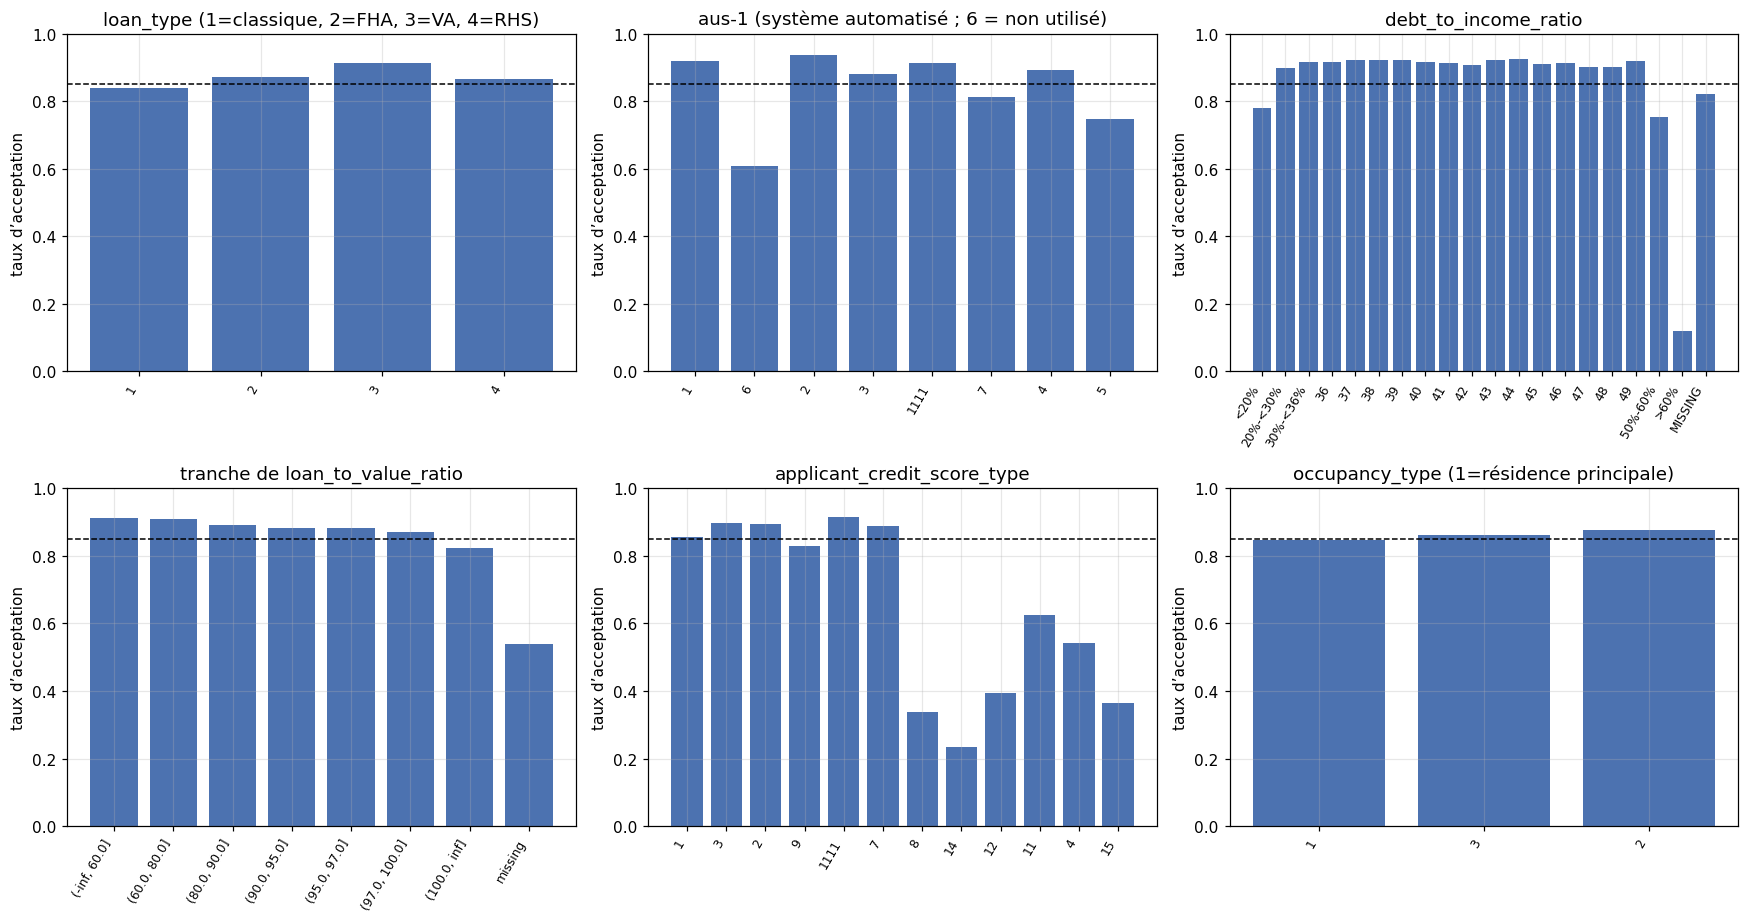

Taux d’acceptation global : 0.850


In [9]:
overall_rate = y.mean()
ltv = X_train['loan_to_value_ratio']
ltv_bins = pd.cut(ltv, [-np.inf, 60, 80, 90, 95, 97, 100, np.inf])
ltv_band = ltv_bins.astype(str).where(ltv.notna(), 'missing')
ltv_order = [str(c) for c in ltv_bins.cat.categories] + ['missing']
dti_order = ['<20%', '20%-<30%', '30%-<36%', *[str(v) for v in range(36, 50)], '50%-60%', '>60%', MISSING_CATEGORY]


def rate_bar(ax, values, title, order=None, top=12):
    table = pd.DataFrame({'v': np.asarray(values), 'y': y.to_numpy()}).groupby('v')['y'].agg(['mean', 'size'])
    table = table.reindex([v for v in order if v in table.index]) if order else \
        table.sort_values('size', ascending=False).head(top)
    ax.bar(range(len(table)), table['mean'], color='#4c72b0')
    ax.axhline(overall_rate, color='black', ls='--', lw=1)
    ax.set_xticks(range(len(table)), [str(v) for v in table.index], rotation=60, ha='right', fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.set_ylabel('taux d’acceptation')


fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
rate_bar(axes[0, 0], X_train['loan_type'], 'loan_type (1=classique, 2=FHA, 3=VA, 4=RHS)')
rate_bar(axes[0, 1], X_train['aus-1'], 'aus-1 (système automatisé ; 6 = non utilisé)')
rate_bar(axes[0, 2], X_train['debt_to_income_ratio'], 'debt_to_income_ratio', order=dti_order)
rate_bar(axes[1, 0], ltv_band, 'tranche de loan_to_value_ratio', order=ltv_order)
rate_bar(axes[1, 1], X_train['applicant_credit_score_type'], 'applicant_credit_score_type')
rate_bar(axes[1, 2], X_train['occupancy_type'], 'occupancy_type (1=résidence principale)')
plt.tight_layout()
plt.show()
print(f'Taux d’acceptation global : {overall_rate:.3f}')

**Valeurs manquantes.** Elles ne sont pas réparties au hasard : le taux d'acceptation change selon qu'un champ est renseigné ou non. On les garde donc telles quelles ; CatBoost les gère directement (`nan_mode=Min`).

,Variable,Lignes manquantes,Acceptation si absente,Acceptation si présente
0,loan_to_value_ratio,11874,0.538,0.890
1,property_value,4756,0.698,0.857
2,income,4578,0.859,0.850
3,loan_term,3307,0.872,0.849
4,debt_to_income_ratio,7679,0.822,0.852
5,applicant_age,3088,0.875,0.849


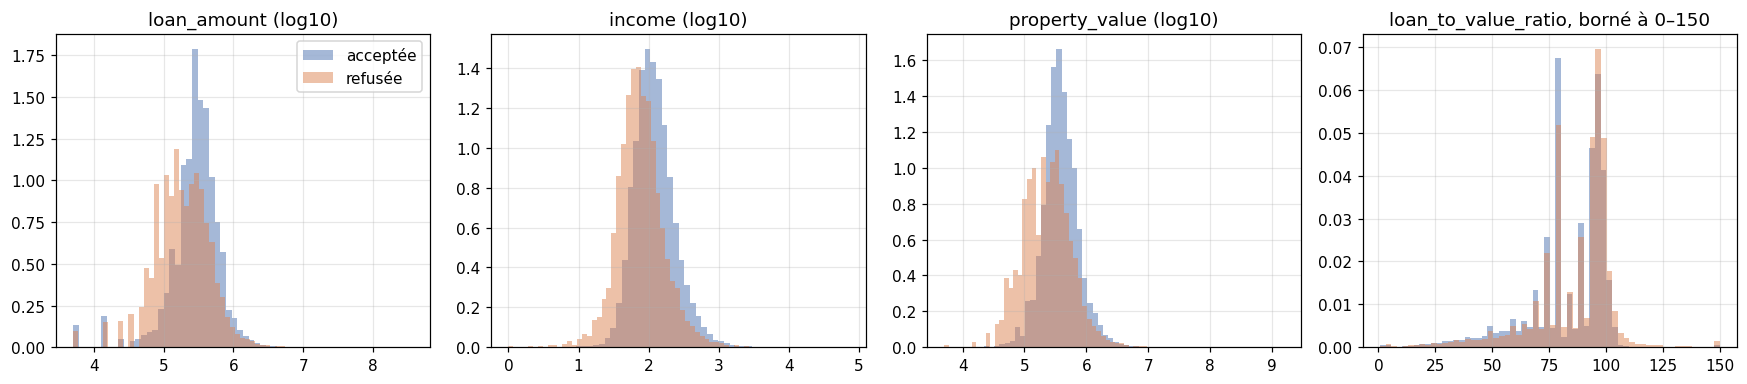

In [10]:
missing_signal = []
for column in ['loan_to_value_ratio', 'property_value', 'income', 'loan_term']:
    mask = X_train[column].isna()
    missing_signal.append({'Variable': column, 'Lignes manquantes': int(mask.sum()),
                           'Acceptation si absente': y[mask].mean(), 'Acceptation si présente': y[~mask].mean()})
for column in ['debt_to_income_ratio', 'applicant_age']:
    mask = X_train[column].eq(MISSING_CATEGORY)
    missing_signal.append({'Variable': column, 'Lignes manquantes': int(mask.sum()),
                           'Acceptation si absente': y[mask].mean(), 'Acceptation si présente': y[~mask].mean()})
display_named(pd.DataFrame(missing_signal).round(3))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (column, use_log, clip) in zip(axes, [('loan_amount', True, None), ('income', True, None),
                                                ('property_value', True, None), ('loan_to_value_ratio', False, (0, 150))]):
    for label, colour, name in [(1, '#4c72b0', 'acceptée'), (0, '#dd8452', 'refusée')]:
        values = X_train.loc[y.eq(label) & X_train[column].notna(), column]
        if use_log:
            values = np.log10(values[values > 0])
        if clip:
            values = values.clip(*clip)
        ax.hist(values, bins=60, density=True, alpha=0.5, color=colour, label=name)
    ax.set_title(column + (' (log10)' if use_log else ', borné à 0–150'))
axes[0].legend()
plt.tight_layout()
plt.show()

## 7. Valeurs inhabituelles

Revenus négatifs ou nuls, très gros montants, LTV au-dessus de 100 %, lignes en double sur toutes les variables : on les compte, on ne les supprime pas.

In [11]:
audit_rows = []
def audit(dataset, check, count, action="\u4fdd\u7559\u5e76\u8bb0\u5f55"):
    audit_rows.append({"dataset": dataset, "check": check, "count": int(count), "action": action})

for name, raw, features in [("train", train_raw, X_train), ("test", test_raw, X_test)]:
    audit(name, "duplicate_ids", raw["id"].duplicated().sum(), "\u5fc5\u987b\u4e3a0\uff1b\u5df2\u6821\u9a8c")
    audit(name, "duplicate_feature_rows_after_first", features.duplicated().sum())
    audit(name, "income_negative", features["income"].lt(0).sum())
    audit(name, "income_zero", features["income"].eq(0).sum())
    audit(name, "ltv_above_200_percent", features["loan_to_value_ratio"].gt(200).sum())
    audit(name, "ltv_above_1000_percent", features["loan_to_value_ratio"].gt(1000).sum(), "\u4fdd\u7559\uff1b\u539f\u59cb\u6765\u6e90\u5f85\u6838\u5b9e")
    audit(name, "negative_housing_age", features["tract_median_age_of_housing_units"].lt(0).sum(), "\u4fdd\u7559\uff1b\u7279\u6b8a\u7f16\u7801\u5f85\u6838\u5b9e")
    for column in ["loan_amount", "property_value", "loan_term"]:
        audit(name, f"{column}_nonpositive", features[column].le(0).sum(), "\u82e5\u975e0\uff0c\u4eba\u5de5\u6838\u67e5")
    audit(name, "minority_percent_outside_0_100", (features["tract_minority_population_percent"].lt(0) | features["tract_minority_population_percent"].gt(100)).sum(), "\u82e5\u975e0\uff0c\u4eba\u5de5\u6838\u67e5")
    for column in feature_columns:
        audit(name, f"blank::{column}", raw[column].str.strip().eq("").sum(), "\u6309\u5b57\u6bb5\u7c7b\u578b\u89c4\u8303\u7f3a\u5931")

# Hash pour l’audit des doublons, sans suppression ni association de cibles
train_feature_hash = pd.util.hash_pandas_object(X_train, index=False)
test_feature_hash = pd.util.hash_pandas_object(X_test, index=False)
audit("train_test", "shared_feature_hash_values", len(set(train_feature_hash) & set(test_feature_hash)), "\u4fdd\u7559\uff1b\u4ec5\u8bca\u65ad\uff0c\u5b58\u5728\u7406\u8bba\u54c8\u5e0c\u78b0\u649e\u53ef\u80fd")
for row in unseen_rows:
    audit("test", f"unseen_category_rows::{row['Champ']}", row["Lignes_test_concernées"], "\u4fdd\u7559\u539f\u7c7b\u522b\uff0c\u6a21\u578b\u5904\u7406\u672a\u89c1\u7c7b\u522b")
audit_table = pd.DataFrame(audit_rows)
# Conserver les valeurs persistées de audit.csv ; traduire uniquement la vue.
audit_action_labels = {
    "\u4fdd\u7559\u5e76\u8bb0\u5f55": 'Conserver et consigner',
    "\u5fc5\u987b\u4e3a0\uff1b\u5df2\u6821\u9a8c": 'Doit valoir 0 ; vérifié',
    "\u4fdd\u7559\uff1b\u539f\u59cb\u6765\u6e90\u5f85\u6838\u5b9e": 'Conserver ; source à vérifier',
    "\u4fdd\u7559\uff1b\u7279\u6b8a\u7f16\u7801\u5f85\u6838\u5b9e": 'Conserver ; code spécial à vérifier',
    "\u82e5\u975e0\uff0c\u4eba\u5de5\u6838\u67e5": 'Vérifier manuellement si non nul',
    "\u6309\u5b57\u6bb5\u7c7b\u578b\u89c4\u8303\u7f3a\u5931": 'Normaliser les valeurs manquantes selon le type du champ',
    "\u4fdd\u7559\uff1b\u4ec5\u8bca\u65ad\uff0c\u5b58\u5728\u7406\u8bba\u54c8\u5e0c\u78b0\u649e\u53ef\u80fd": 'Conserver ; diagnostic seulement, collisions de hash théoriquement possibles',
    "\u4fdd\u7559\u539f\u7c7b\u522b\uff0c\u6a21\u578b\u5904\u7406\u672a\u89c1\u7c7b\u522b": 'Conserver la catégorie ; le modèle gère les modalités inédites',
}
audit_display = audit_table[~audit_table["check"].str.startswith("blank::")].copy()
audit_display["action"] = audit_display["action"].replace(audit_action_labels)
display_named(audit_display)

,dataset,check,count,action
0,train,duplicate_ids,0,Doit valoir 0 ; vérifié
1,train,duplicate_feature_rows_after_first,7,Conserver et consigner
2,train,income_negative,28,Conserver et consigner
3,train,income_zero,926,Conserver et consigner
4,train,ltv_above_200_percent,34,Conserver et consigner
5,train,ltv_above_1000_percent,3,Conserver ; source à vérifier
6,train,negative_housing_age,5,Conserver ; code spécial à vérifier
7,train,loan_amount_nonpositive,0,Vérifier manuellement si non nul
8,train,property_value_nonpositive,0,Vérifier manuellement si non nul
9,train,loan_term_nonpositive,0,Vérifier manuellement si non nul


## 8. Contrôles de qualité

- **Validation adversariale** : un modèle essaie de distinguer apprentissage et test. Une AUC proche de 0.5 veut dire qu'il n'y arrive pas.
- **Identifiants** : sont-ils liés à la cible, deux identifiants voisins se ressemblent-ils ?
- **Champs dérivés** : sont-ils cohérents avec les champs dont ils viennent ?
- **Valeurs inhabituelles** : quel taux d'acceptation dans ces groupes ?

In [12]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score

combined = pd.concat([X_train, X_test], ignore_index=True)
encoded = combined.copy()
for column in categorical_columns:
    encoded[column] = encoded[column].astype('category').cat.codes
is_test = np.r_[np.zeros(len(X_train)), np.ones(len(X_test))]
adversarial_auc = cross_val_score(
    HistGradientBoostingClassifier(max_iter=200, random_state=RANDOM_STATE), encoded, is_test,
    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE), scoring='roc_auc').mean()

train_id_values = pd.to_numeric(train_labels['id'])
test_id_values = pd.to_numeric(test_ids['id'])
sorted_labels = y.to_numpy()[np.argsort(train_id_values.to_numpy())].astype(float)
window = 5
neighbour_sum = pd.Series(sorted_labels).rolling(2 * window + 1, center=True, min_periods=1).sum() - sorted_labels
neighbour_count = pd.Series(np.ones(len(sorted_labels))).rolling(2 * window + 1, center=True, min_periods=1).sum() - 1
neighbour_corr = np.corrcoef(sorted_labels, neighbour_sum / neighbour_count)[0, 1]

loan_type_name = X_train['loan_type'].map({'1': 'Conventional', '2': 'FHA', '3': 'VA', '4': 'FSA/RHS'})
lien_name = X_train['lien_status'].map({'1': 'First Lien', '2': 'Subordinate Lien'})
construction_name = X_train['construction_method'].map({'1': 'Site-Built', '2': 'Manufactured'})
checks = pd.DataFrame([
    ('AUC adversariale train/test (0,5 = absence de séparation détectée)', f'{adversarial_auc:.4f}'),
    ('AUC de la cible prédite par l’ID seul', f'{roc_auc_score(y, train_id_values):.4f}'),
    ('Corrélation de la cible avec la moyenne des 10 ID voisins', f'{neighbour_corr:.4f}'),
    ('Plage des ID : train / test', f'{train_id_values.min()}–{train_id_values.max()} / '
                           f'{test_id_values.min()}–{test_id_values.max()}'),
    ('Produit = type de prêt + rang de garantie', f"{(loan_type_name + ':' + lien_name).eq(X_train['derived_loan_product_type']).mean():.2%}"),
    ('Cohérence entre catégorie de logement et construction',
     f"{X_train['derived_dwelling_category'].str.split(':').str[1].eq(construction_name).mean():.2%}"),
], columns=['Contrôle', 'Résultat'])
display_named(checks)

loan_to_value_raw = X_train['loan_amount'] / X_train['property_value']
anomalies = {
    'Ensemble': pd.Series(True, index=X_train.index),
    'LTV absent': ltv.isna(),
    'LTV > 150': ltv > 150,
    'Population du secteur = 0': X_train['tract_population'].eq(0),
    'Revenu régional = 0': X_train['ffiec_msa_md_median_family_income'].eq(0),
    'Montant du prêt / valeur du bien > 2': loan_to_value_raw > 2,
    'Revenu ≤ 0': X_train['income'] <= 0,
}
display_named(pd.DataFrame([{'Cas': name, 'Lignes': int(mask.sum()), 'Taux d’acceptation': y[mask].mean()}
                      for name, mask in anomalies.items()]).round(3))

,Contrôle,Résultat
0,"AUC adversariale train/test (0,5 = absence de séparation détectée)",0.5007
1,AUC de la cible prédite par l’ID seul,0.4957
2,Corrélation de la cible avec la moyenne des 10 ID voisins,0.0031
3,Plage des ID : train / test,100000–599996 / 600005–999992
4,Produit = type de prêt + rang de garantie,100.00%
5,Cohérence entre catégorie de logement et construction,100.00%


,Cas,Lignes,Taux d’acceptation
0,Ensemble,105000,0.850
1,LTV absent,11874,0.538
2,LTV > 150,114,0.702
3,Population du secteur = 0,2117,0.171
4,Revenu régional = 0,1330,0.241
5,Montant du prêt / valeur du bien > 2,148,0.135
6,Revenu ≤ 0,954,0.561


Apprentissage et test se ressemblent, les identifiants ne portent pas de signal et les champs dérivés sont cohérents. Les groupes aux valeurs inhabituelles sont moins souvent acceptés, ce qui est une information utile : on garde ces lignes.

## 9. Cinq plis fixes

`StratifiedKFold(5, shuffle=True, random_state=42)`. Toutes les expériences utilisent ce découpage, ce qui permet de comparer deux variantes pli par pli.

In [13]:
assert y.value_counts().min() >= N_SPLITS
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
fold_assignment = np.zeros(len(y), dtype="int8")
validation_seen = np.zeros(len(y), dtype="int8")
for fold, (fit_idx, valid_idx) in enumerate(cv.split(X_train, y), start=1):
    assert len(np.intersect1d(fit_idx, valid_idx)) == 0
    assert len(fit_idx) + len(valid_idx) == len(y)
    fold_assignment[valid_idx] = fold
    validation_seen[valid_idx] += 1
assert np.all(validation_seen == 1)
assert set(fold_assignment.tolist()) == set(range(1, N_SPLITS + 1))
folds = pd.DataFrame({"id": train_labels["id"], "fold": fold_assignment})
fold_profile = train_labels.assign(fold=fold_assignment).groupby("fold")["accepted"].agg(["size", "mean"])
fold_profile.columns = ["Lignes_validation", "Taux_approbation_validation"]
display_named(fold_profile)

,Lignes_validation,Taux_approbation_validation
fold,,
1,21000,0.849952
2,21000,0.849952
3,21000,0.849952
4,21000,0.849952
5,21000,0.849905


## 10. Enregistrement

`train_features.csv` et `test_features.csv` contiennent les 56 variables ; d'autres fichiers gardent la cible, les identifiants et les plis. `schema.json` décrit les types et `manifest.json` les empreintes SHA-256, que les notebooks suivants vérifient avant de commencer. Les fichiers existants ne sont pas réécrits, sauf si `REBUILD_PREPARED` est activé.

In [14]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


if REBUILD_PREPARED or not (PREPARED_DIR / "manifest.json").is_file():
    PREPARED_DIR.mkdir(parents=True, exist_ok=True)
    output_frames = {
        "train_features.csv": X_train, "test_features.csv": X_test,
        "train_labels.csv": train_labels, "test_ids.csv": test_ids,
        "folds.csv": folds, "audit.csv": audit_table,
    }
    for name, frame in output_frames.items():
        destination = PREPARED_DIR / name
        temporary = destination.with_suffix(destination.suffix + ".tmp")
        frame.to_csv(temporary, index=False, na_rep="")
        temporary.replace(destination)
    (PREPARED_DIR / "schema.json").write_text(json.dumps(schema, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

    manifest = {
        "schema_version": SCHEMA_VERSION,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "source_dir": str(DATA_DIR),
        "source_files": {name: {"sha256": sha256_file(DATA_DIR / name), "bytes": (DATA_DIR / name).stat().st_size} for name in SOURCE_FILES},
        "output_files": {name: {"sha256": sha256_file(PREPARED_DIR / name), "bytes": (PREPARED_DIR / name).stat().st_size} for name in [*output_frames, "schema.json"]},
        "n_rows": {"train": len(X_train), "test": len(X_test)},
        "n_features": len(feature_columns),
        "seed": RANDOM_STATE, "n_splits": N_SPLITS,
        "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__},
        "preprocessing": "deterministic text/type normalization only; no fitted estimator or population-derived threshold",
    }
    # Écrire le manifeste en dernier ; en cas d’échec, les empreintes incompatibles bloquent les modèles
    manifest_temp = PREPARED_DIR / "manifest.json.tmp"
    manifest_temp.write_text(json.dumps(manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    manifest_temp.replace(PREPARED_DIR / "manifest.json")
    print(f"Enregistrés : {len(output_frames) + 2} fichiers préparés.")
else:
    manifest = json.loads((PREPARED_DIR / "manifest.json").read_text(encoding="utf-8"))
    print("artifacts/01_data_exploration existe déjà ; la cellule suivante compare les fichiers conservés aux données préparées en mémoire.")

artifacts/01_data_exploration existe déjà ; la cellule suivante compare les fichiers conservés aux données préparées en mémoire.


## 11. Relecture

On relit les fichiers enregistrés et on les compare aux données recalculées : valeurs, catégories, ordre des colonnes, identifiants, plis, empreintes.

In [15]:
def read_prepared_features(path, saved_schema):
    frame = read_text_csv(path)
    assert frame.columns.tolist() == saved_schema["feature_columns"]
    for column in saved_schema["numeric_columns"]:
        frame[column] = pd.to_numeric(frame[column].replace("", np.nan), errors="raise").astype("float64")
    for column in saved_schema["categorical_columns"]:
        assert frame[column].ne("").all(), f"{column}: catégorie vide dans le fichier préparé"
        frame[column] = frame[column].astype(object)
    return frame

saved_schema = json.loads((PREPARED_DIR / "schema.json").read_text(encoding="utf-8"))
for name, expected in [("train_features.csv", X_train), ("test_features.csv", X_test)]:
    restored = read_prepared_features(PREPARED_DIR / name, saved_schema)
    pd.testing.assert_frame_equal(restored, expected, check_exact=False, rtol=1e-14, atol=0)
pd.testing.assert_frame_equal(read_text_csv(PREPARED_DIR / "train_labels.csv"), train_labels.astype(str))
pd.testing.assert_frame_equal(read_text_csv(PREPARED_DIR / "test_ids.csv"), test_ids)
pd.testing.assert_frame_equal(read_text_csv(PREPARED_DIR / "folds.csv"), folds.astype(str))
for name, entry in manifest["output_files"].items():
    assert sha256_file(PREPARED_DIR / name) == entry["sha256"], f"Empreinte du fichier de sortie modifiée : {name}"
print("Relecture, types, alignement des lignes et empreintes SHA-256 vérifiés.")

Relecture, types, alignement des lignes et empreintes SHA-256 vérifiés.
